# Toronto Bike Share Viz Lab — Summer 2026 smoke test

Runs independently of CSC's 2024 routing database. Checks the **official City of Toronto CKAN catalogue** for 2026 resources, downloads candidate files, extracts June–August 2026 trip records, and draws daily ridership / electric-bike share. If the City has not published a given month, it cannot be visualised yet.

**Important:** This is a test, not a claim that 2026 summer data are already published or that bike-share OD lines are observed GPS trajectories. Attribution: City of Toronto, *Bike Share Toronto Ridership Data*, Open Government Licence – Toronto. Dataset: https://open.toronto.ca/dataset/bike-share-toronto-ridership-data/

In [1]:
from pathlib import Path
import io, re, zipfile, requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PROJECT = Path.cwd()
if not (PROJECT / 'scripts').exists() and (PROJECT.parent / 'scripts').exists():
    PROJECT = PROJECT.parent
assert (PROJECT / 'scripts').exists(), 'Open notebook from the repository or notebooks/ directory'
RAW = PROJECT / 'data' / 'raw'
OUT = PROJECT / 'outputs' / 'summer_2026'
RAW.mkdir(parents=True, exist_ok=True)
OUT.mkdir(parents=True, exist_ok=True)
YEAR = 2026
MONTHS = (6, 7, 8)
DATASET = 'bike-share-toronto-ridership-data'
API = 'https://ckan0.cf.opendata.inter.prod-toronto.ca/api/3/action/package_show'
print('Project:', PROJECT)

Project: /scratch/project_2010417/paper3/toronto-bikeshare-viz


In [2]:
# Inspect what's actually published. No assumptions about the resource packaging.
response = requests.get(API, params={'id': DATASET}, timeout=90)
response.raise_for_status()
api_response = response.json()
assert api_response.get('success'), 'City CKAN catalogue response was unsuccessful'
resources = pd.DataFrame([{
    'name': r.get('name', ''), 'format': r.get('format', ''),
    'url': r.get('url', ''), 'modified': r.get('last_modified', '')
} for r in api_response['result']['resources']])
display(resources.tail(25))
mask2026 = resources['name'].astype(str).str.contains(r'2026', case=False, na=False) | resources['url'].astype(str).str.contains(r'2026', case=False, na=False)
candidates = resources[mask2026].copy()
print(f'2026 candidate resources: {len(candidates)}')
display(candidates)
if candidates.empty:
    print('No 2026 resource identified. The City might not have published it yet, or naming may have changed.')

,name,format,url,modified
0,bikeshare-ridership-readme,XLSX,https://ckan0.cf.opendata.inter.prod-toronto.c...,2022-04-12T14:38:55
1,bikeshare-ridership-2014-2015,XLSX,https://ckan0.cf.opendata.inter.prod-toronto.c...,2022-04-11T15:42:55
2,bikeshare-ridership-2016,XLSX,https://ckan0.cf.opendata.inter.prod-toronto.c...,2022-04-11T15:48:24
3,bikeshare-ridership-2017.zip,ZIP,https://opendata.toronto.ca/toronto.parking.au...,2022-04-11T15:48:57
4,bikeshare-ridership-2018.zip,ZIP,https://opendata.toronto.ca/toronto.parking.au...,2022-04-11T15:52:05
5,bikeshare-ridership-2019.zip,ZIP,https://opendata.toronto.ca/toronto.parking.au...,2022-04-11T15:55:06
6,bikeshare-ridership-2020.zip,ZIP,https://opendata.toronto.ca/toronto.parking.au...,2022-04-11T15:55:11
7,bikeshare-ridership-2021.zip,ZIP,https://opendata.toronto.ca/toronto.parking.au...,2022-04-11T16:01:24
8,bikeshare-ridership-2022.zip,ZIP,https://opendata.toronto.ca/toronto.parking.au...,2023-01-18T17:36:31
9,bikeshare-ridership-2023.zip,ZIP,https://opendata.toronto.ca/toronto.parking.au...,2024-01-09T17:24:07


2026 candidate resources: 1


,name,format,url,modified
12,bikeshare-ridership-2026.zip,ZIP,https://opendata.toronto.ca/toronto.parking.au...,2026-10-13T12:28:46


In [3]:
# Download candidate data resources ONLY (exclude documentation).
# For a very large annual file, allow enough time/storage on CSC.
files=[]
for idx, r in candidates.iterrows():
    url = r['url']
    suffix = '.zip' if '.zip' in url.lower() or 'zip' in str(r['format']).lower() else '.csv' if '.csv' in url.lower() or 'csv' in str(r['format']).lower() else None
    if suffix is None:
        print('Skipping non-CSV/ZIP candidate:', r['name']); continue
    dest = RAW / f'summer2026_resource_{idx}{suffix}'
    if not dest.exists():
        print('Downloading:', r['name'])
        with requests.get(url, stream=True, timeout=180) as response:
            response.raise_for_status()
            with dest.open('wb') as f:
                for chunk in response.iter_content(chunk_size=1024*1024):
                    if chunk: f.write(chunk)
    print('Available:', dest, f'{dest.stat().st_size/1e6:.1f} MB')
    files.append(dest)
print('Downloaded/reused files:', len(files))

Downloading: bikeshare-ridership-2026.zip
Available: /scratch/project_2010417/paper3/toronto-bikeshare-viz/data/raw/summer2026_resource_12.zip 204.0 MB
Downloaded/reused files: 1


In [4]:
# Read ZIP/CSV incrementally and detect start-time column across possible schemas.
# This cell deliberately does not assume the 2024 naming convention remains unchanged.
def standardize_columns(df):
    df = df.copy()
    df.columns = [re.sub(r'[^a-z0-9]+', '_', str(c).lower()).strip('_') for c in df.columns]
    options = ['start_time','trip_start_time','trip_start','started_at','start_date']
    col = next((c for c in options if c in df.columns), None)
    if col is None:
        raise ValueError(f'No recognisable trip start time. Available columns: {list(df.columns)}')
    df['date_time'] = pd.to_datetime(df[col], errors='coerce')
    df = df[df['date_time'].dt.year.eq(YEAR) & df['date_time'].dt.month.isin(MONTHS)].copy()
    return df

pieces=[]
for source in files:
    if source.suffix.lower() == '.zip':
        with zipfile.ZipFile(source) as z:
            csvs = [f for f in z.namelist() if f.lower().endswith('.csv') and not f.startswith('__MACOSX')]
            print(source.name, 'CSV members:', len(csvs))
            for member in csvs:
                with z.open(member) as stream:
                    for chunk in pd.read_csv(stream, chunksize=150_000, low_memory=False, dtype=str):
                        result = standardize_columns(chunk)
                        if len(result): pieces.append(result)
    elif source.suffix.lower() == '.csv':
        for chunk in pd.read_csv(source, chunksize=150_000, low_memory=False, dtype=str):
            result = standardize_columns(chunk)
            if len(result): pieces.append(result)

if not pieces:
    print('No summer 2026 trips available in the identified resources. Stop here and inspect the catalogue.')
else:
    trips = pd.concat(pieces, ignore_index=True)
    if 'trip_id' in trips.columns:
        before = len(trips)
        trips = trips.drop_duplicates(subset='trip_id')
        print('Removed duplicate trip IDs:', before-len(trips))
    trips['day'] = trips['date_time'].dt.normalize()
    print(f'Loaded {len(trips):,} summer 2026 records')
    print('Columns:', list(trips.columns))
    display(trips.groupby(trips['day'].dt.month).size().rename('trips'))

summer2026_resource_12.zip CSV members: 1
Removed duplicate trip IDs: 0
Loaded 3,698,997 summer 2026 records
Columns: ['trip_id', 'trip_duration', 'start_station_id', 'start_time', 'start_station_name', 'end_station_id', 'end_time', 'end_station_name', 'bike_id', 'user_type', 'bike_model', 'date_time', 'day']


day
6    1173371
7    1261716
8    1263910
Name: trips, dtype: int64

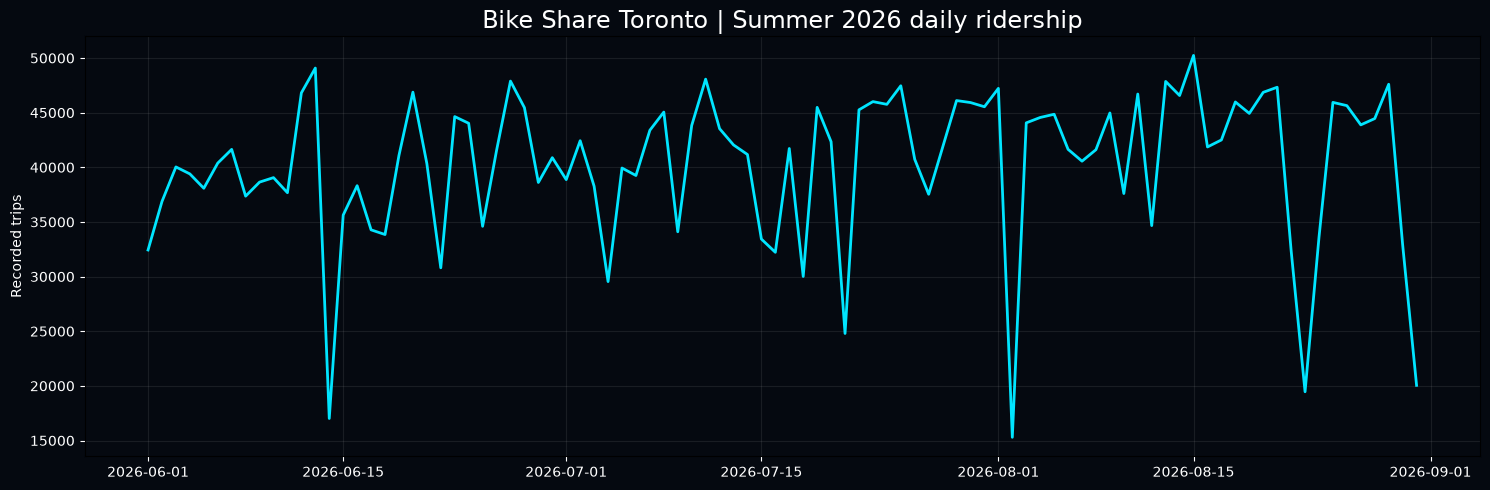

In [5]:
# Chart 1 — daily ridership (only days represented in the actual downloads).
if 'trips' in globals() and len(trips):
    daily = trips.groupby('day').size().rename('trips')
    fig, ax = plt.subplots(figsize=(15, 5), facecolor='#050910')
    ax.set_facecolor('#050910')
    ax.plot(daily.index, daily.values, color='#00e5ff', lw=2)
    ax.set_title('Bike Share Toronto | Summer 2026 daily ridership', color='white', fontsize=17)
    ax.set_ylabel('Recorded trips', color='white')
    ax.tick_params(colors='white'); ax.grid(alpha=.12)
    fig.tight_layout()
    fig.savefig(OUT/'daily_ridership_2026.png', dpi=180, facecolor=fig.get_facecolor())
    plt.show()

Source model values:


bike_model
ICONIC    2823651
EFIT       830583
ASTRO       44763
Name: count, dtype: int64

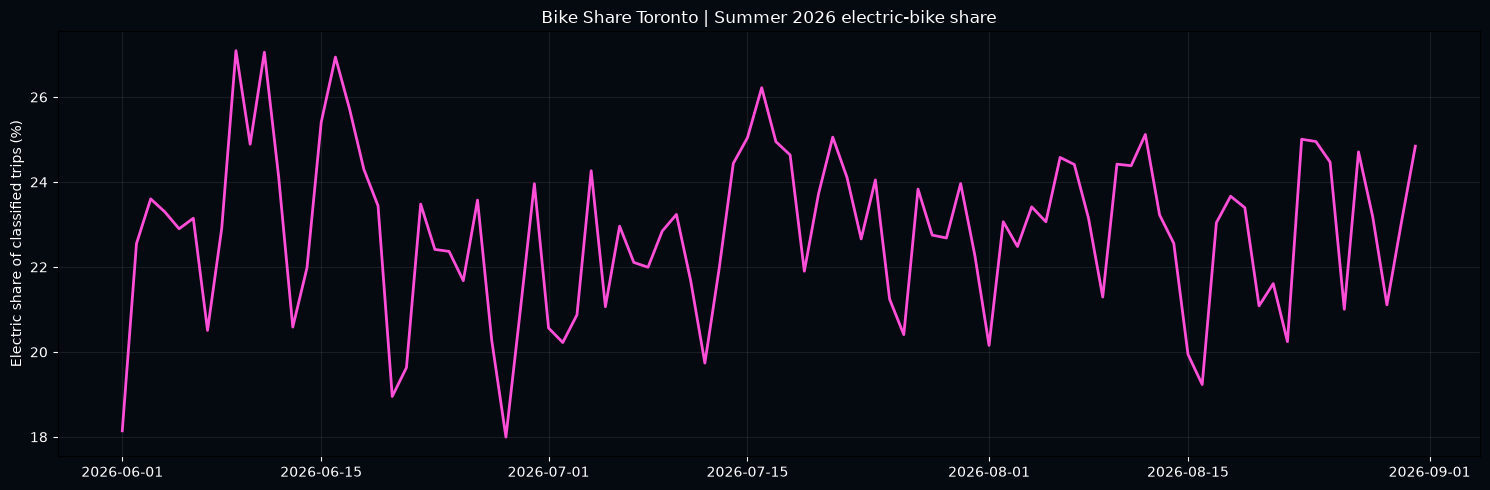

In [6]:
# Chart 2 — electric share by day, only if the published data contains a bike model.
if 'trips' in globals() and len(trips):
    model_col = next((c for c in ['bike_model','bike_type','vehicle_type'] if c in trips.columns), None)
    if model_col is None:
        print('No Bike_Model-like column in the 2026 source; e-bike comparison unavailable.')
    else:
        print('Source model values:')
        display(trips[model_col].value_counts(dropna=False).head(25))
        model = trips[model_col].fillna('').astype(str).str.upper().str.strip()
        # Match the 2024 Toronto model naming, but inspect values above before relying on classification.
        bike_type = np.select([model.str.startswith('EFIT'),model.eq('ICONIC')], ['Electric','Conventional'],default='Other / unknown')
        tab = pd.crosstab(trips['day'], bike_type)
        if 'Electric' in tab.columns and 'Conventional' in tab.columns:
            share = 100 * tab['Electric'] / (tab['Electric']+tab['Conventional']).replace(0,np.nan)
            fig, ax = plt.subplots(figsize=(15,5), facecolor='#050910')
            ax.set_facecolor('#050910')
            ax.plot(share.index, share.values, color='#ff4fd8', linewidth=2)
            ax.set_ylabel('Electric share of classified trips (%)', color='white')
            ax.set_title('Bike Share Toronto | Summer 2026 electric-bike share', color='white')
            ax.tick_params(colors='white'); ax.grid(alpha=.12)
            fig.tight_layout()
            fig.savefig(OUT/'electric_share_2026.png', dpi=180, facecolor=fig.get_facecolor())
            plt.show()
        else:
            print('No usable EFIT/ICONIC pair of categories; revise mapping after inspecting source labels.')

## Interpretation and next step

- **Missing days are not zero-ridership days.** Check whether each month is actually published and whether partial months are present.
- Monthly and daily counts can be compared immediately. A glowing street-network map requires station locations and a newly routed 2026 OD network; **do not use the 2024 SQLite routes as verified 2026 routes**.
- Station coordinates fetched from the current GBFS feed are snapshots, not proof of where a station stood throughout the summer.
- If the catalogue has no 2026 resource, use the existing 2024 workflows for an end-to-end software test and rerun this notebook when the 2026 ridership data appears.
